# Primer Modelo de Predicción con Red Neuronal

## Introducción a las Redes Neuronales para Regresión

### Las redes neuronales son modelos computacionales inspirados en el cerebro humano que pueden aprender patrones complejos en los datos. Para problemas de regresión, aprenden a mapear variables de entrada a valores continuos de salida.

## Arquitectura Básica de una Red Neuronal
 
#### - **Capa de entrada**: Recibe las features
#### - **Capas ocultas**: Transformaciones no lineales
#### - **Capa de salida**: Produce la predicción
#### - **Neuronas**: Unidades computacionales básicas
#### - **Conexiones**: Pesos que se ajustan durante el entrenamiento

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import warnings
warnings.filterwarnings('ignore')

In [5]:
plt.style.use('default')
sns.set_palette("husl")
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")


TensorFlow version: 2.20.0
Keras version: 3.11.3


## Generación de Datos de Ejemplo
 
#### Vamos a crear un dataset sintético con relaciones no lineales para demostrar el poder de las redes neuronales.


In [8]:
def generar_datos_no_lineales(n_muestras=1000, ruido=0.1):
    """
    Genera datos con relaciones no lineales complejas
    y = 2*x1 + 3*x2^2 + sin(4*x3) + 0.5*x1*x2 + ruido
    """
    np.random.seed(42)
    
    # Generar features
    x1 = np.random.normal(0, 1, n_muestras)
    x2 = np.random.normal(0, 1, n_muestras)
    x3 = np.random.normal(0, 1, n_muestras)
    x4 = np.random.normal(0, 1, n_muestras)
    
    # Crear variable objetivo con relaciones no lineales
    y = (2 * x1 + 
         3 * x2**2 + 
         np.sin(4 * x3) + 
         0.5 * x1 * x2 + 
         np.random.normal(0, ruido, n_muestras))
    
    # Crear DataFrame
    datos = pd.DataFrame({
        'feature1': x1,
        'feature2': x2,
        'feature3': x3,
        'feature4': x4,
        'target': y
    })
    
    return datos

In [10]:
# llamemos a los datos que acabamos de generar
datos = generar_datos_no_lineales(1500)
print("Dimensiones del dataset:", datos.shape)
print("\nPrimeras 5 filas:")
print(datos.head())

Dimensiones del dataset: (1500, 5)

Primeras 5 filas:
   feature1  feature2  feature3  feature4    target
0  0.496714  0.778361 -1.907808 -0.958778  1.917576
1 -0.138264 -0.551186 -0.860385 -1.352509  0.905370
2  0.647689 -0.818199 -0.413606 -1.583588  1.948045
3  1.523030 -0.003374  1.887688  0.412999  3.943101
4 -0.234153 -0.170185  0.556553 -0.214068  0.409886


In [12]:
# Análisis exploratorio de los datos
print("Estadísticas descriptivas:")
print(datos.describe())

Estadísticas descriptivas:
          feature1     feature2     feature3     feature4       target
count  1500.000000  1500.000000  1500.000000  1500.000000  1500.000000
mean      0.049050     0.014952    -0.043824    -0.032663     3.033178
std       0.990223     0.983415     1.015719     1.002194     4.786591
min      -3.241267    -3.019512    -3.007632    -3.176704    -6.144502
25%      -0.624031    -0.635411    -0.735670    -0.679768     0.130548
50%       0.050403    -0.002042    -0.021076    -0.024863     1.970373
75%       0.680073     0.670695     0.612384     0.644844     4.647738
max       3.852731     3.926238     3.243093     3.112910    47.547693


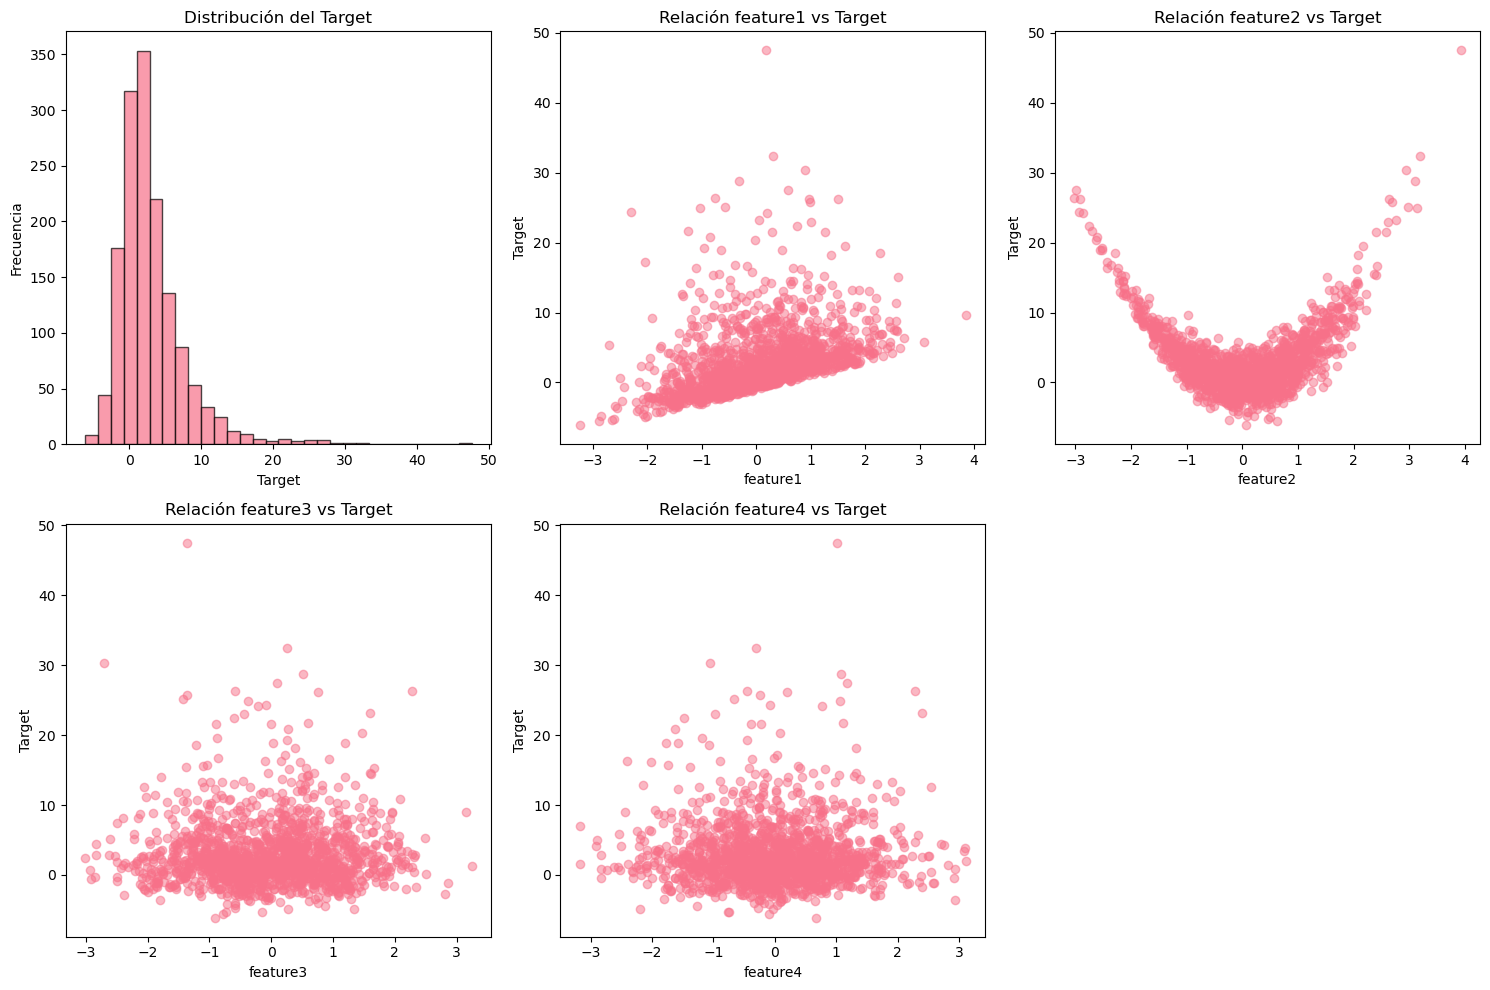

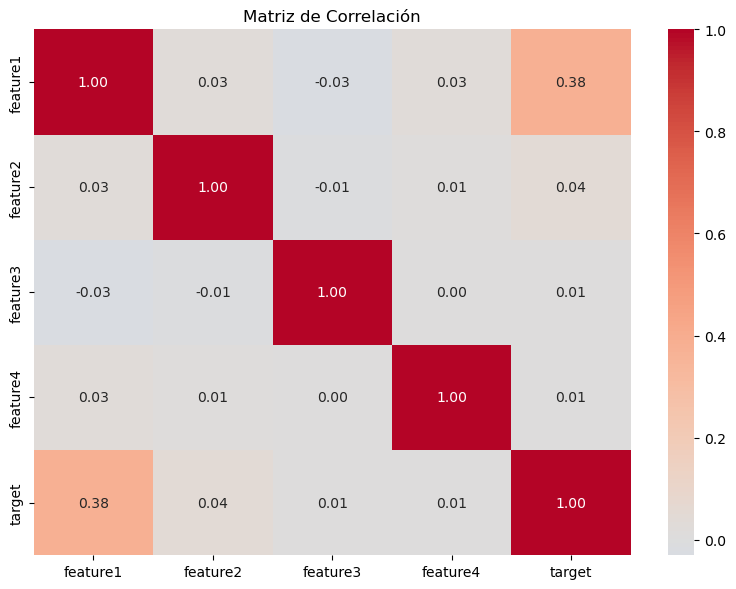

In [24]:
# Visualizar relaciones entre variables 
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()  # Convertir matriz 2x3 a array 1D de 6 elementos

# Distribución del target
axes[0].hist(datos['target'], bins=30, alpha=0.7, edgecolor='black')
axes[0].set_title('Distribución del Target')
axes[0].set_xlabel('Target')
axes[0].set_ylabel('Frecuencia')

# Relaciones con el target
features = ['feature1', 'feature2', 'feature3', 'feature4']
for i, feature in enumerate(features):
    axes[i+1].scatter(datos[feature], datos['target'], alpha=0.5)
    axes[i+1].set_title(f'Relación {feature} vs Target')
    axes[i+1].set_xlabel(feature)
    axes[i+1].set_ylabel('Target')

# Ocultar el subplot sobrante (si hay más de 5)
if len(features) + 1 < len(axes):
    axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

# Matriz de correlación
plt.figure(figsize=(8, 6))
corr_matrix = datos.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Matriz de Correlación')
plt.tight_layout()
plt.show()

## Preprocesamiento de Datos
 
### Pasos críticos para redes neuronales:

### 1. **División train/test**: Separar datos para evaluación
### 2. **Escalado**: Las redes neuronales son sensibles a la escala
### 3. **Validación**: Conjunto de validación para monitorear entrenamiento


In [27]:
# Preparación de datos para el modelo
X = datos[['feature1', 'feature2', 'feature3', 'feature4']]
y = datos['target']

# División en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# División adicional para validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

print(f"Tamaño conjunto de entrenamiento: {X_train.shape}")
print(f"Tamaño conjunto de validación: {X_val.shape}")
print(f"Tamaño conjunto de prueba: {X_test.shape}")

Tamaño conjunto de entrenamiento: (960, 4)
Tamaño conjunto de validación: (240, 4)
Tamaño conjunto de prueba: (300, 4)


In [29]:
# Escalado de características (CRÍTICO para redes neuronales)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nEstadísticas después del escalado:")
print(f"Media X_train: {np.mean(X_train_scaled, axis=0)}")
print(f"Desviación X_train: {np.std(X_train_scaled, axis=0)}")


Estadísticas después del escalado:
Media X_train: [-2.31296463e-17  5.08852220e-18 -1.01770444e-17  2.22044605e-17]
Desviación X_train: [1. 1. 1. 1.]


# Construcción del Primer Modelo de Red Neuronal
 
### Hiperparámetros clave:

### - **Capas y neuronas**: Arquitectura de la red
### - **Función de activación**: Introduce no linealidad
### - **Optimizador**: Algoritmo de aprendizaje
### - **Función de pérdida**: Métrica a optimizar
### - **Tasa de aprendizaje**: Velocidad de aprendizaje

In [32]:
# Construcción del modelo secuencial
modelo = keras.Sequential([
    # Capa de entrada (4 features) + primera capa oculta
    layers.Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    
    # Segunda capa oculta
    layers.Dense(32, activation='relu'),
    
    # Tercera capa oculta
    layers.Dense(16, activation='relu'),
    
    # Capa de salida (1 neurona para regresión, sin activación)
    layers.Dense(1)  # No activation for regression
])

# Compilación del modelo
modelo.compile(
    optimizer='adam',           # Optimizador adaptativo
    loss='mse',                # Mean Squared Error para regresión
    metrics=['mae']            # Mean Absolute Error para monitoreo
)

print("Resumen de la arquitectura del modelo:")
modelo.summary()

Resumen de la arquitectura del modelo:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento del Modelo
 
#### Conceptos importantes:
#### - Epoch: Paso completo sobre todo el dataset
#### - Batch: Subconjunto de datos para actualización de pesos
#### - Loss: Error del modelo (a minimizar)
#### - Validation: Monitoreo de sobreajuste

In [35]:
# Configuración del entrenamiento
history = modelo.fit(
    X_train_scaled, y_train,
    epochs=100,                   # Número de épocas
    batch_size=32,               # Tamaño del lote
    validation_data=(X_val_scaled, y_val),
    verbose=1,                   # Mostrar progreso
    callbacks=[
        # Early stopping para prevenir overfitting
        keras.callbacks.EarlyStopping(
            patience=10,         # Paciencia antes de parar
            restore_best_weights=True
        )
    ]
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 25.8097 - mae: 3.2905 - val_loss: 22.9295 - val_mae: 3.1029
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 18.4554 - mae: 2.7193 - val_loss: 14.8741 - val_mae: 2.6097
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 13.0714 - mae: 2.5050 - val_loss: 11.1983 - val_mae: 2.3675
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 9.8607 - mae: 2.1452 - val_loss: 7.8959 - val_mae: 1.9543
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.7499 - mae: 1.7645 - val_loss: 4.9662 - val_mae: 1.5248
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.1789 - mae: 1.3474 - val_loss: 3.0039 - val_mae: 1.2068
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.6447 - mae: 1.0899 - val_loss: 2.2355 - val_mae: 1.0877
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.0656 - mae: 1.0050 - val_loss: 2.0689 - val_mae: 1.0831
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss:

## Análisis del Proceso de Entrenamiento
 
### Patrones a observar:
### - Convergencia: La loss debería disminuir y estabilizarse
### - Overfitting: Brecha entre train/validation loss
### - Estabilidad: Entrenamiento sin oscilaciones bruscas

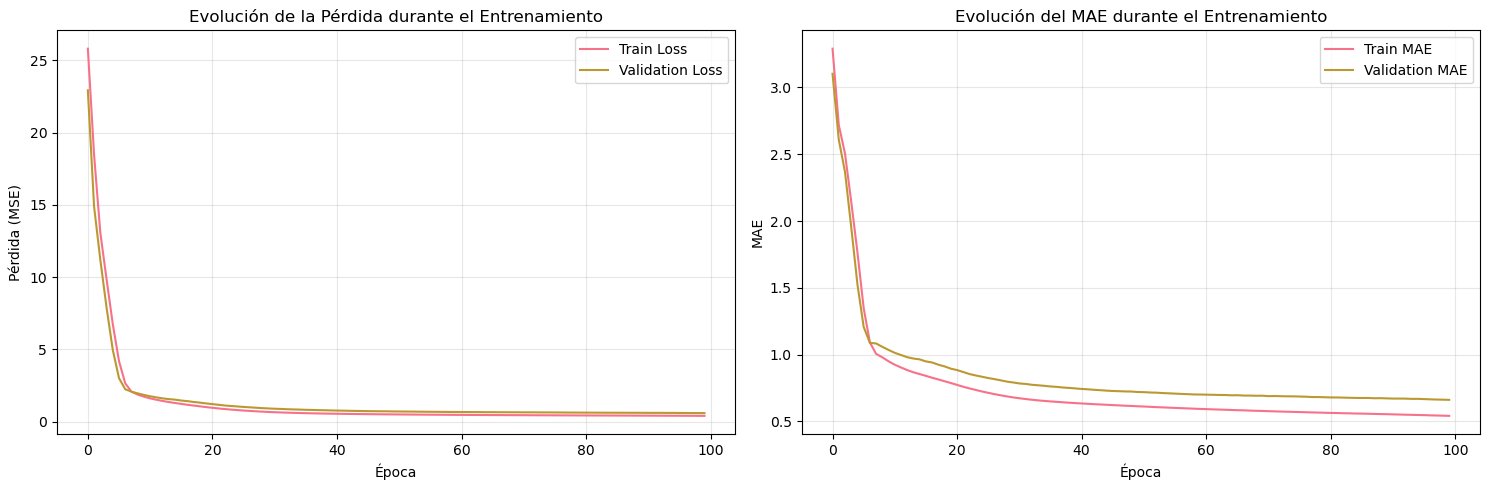

In [40]:
# Visualización del entrenamiento
plt.figure(figsize=(15, 5))

# Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Evolución de la Pérdida durante el Entrenamiento')
plt.xlabel('Época')
plt.ylabel('Pérdida (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)

# Error Absoluto Medio (MAE)
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Evolución del MAE durante el Entrenamiento')
plt.xlabel('Época')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Análisis del entrenamiento
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
final_train_mae = history.history['mae'][-1]
final_val_mae = history.history['val_mae'][-1]

print(f"Pérdida final - Entrenamiento: {final_train_loss:.4f}")
print(f"Pérdida final - Validación: {final_val_loss:.4f}")
print(f"MAE final - Entrenamiento: {final_train_mae:.4f}")
print(f"MAE final - Validación: {final_val_mae:.4f}")

Pérdida final - Entrenamiento: 0.3919
Pérdida final - Validación: 0.5828
MAE final - Entrenamiento: 0.5411
MAE final - Validación: 0.6611


## Evaluación del Modelo en Datos de Prueba
 
### Métricas clave para regresión:
### - MSE (Mean Squared Error): Penaliza errores grandes
### - MAE (Mean Absolute Error): Interpretación directa
### - R² (R-squared): Proporción de varianza explicada

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Métricas de evaluación en conjunto de prueba:
MSE: 0.8007
RMSE: 0.8948
MAE: 0.6911
R²: 0.9739


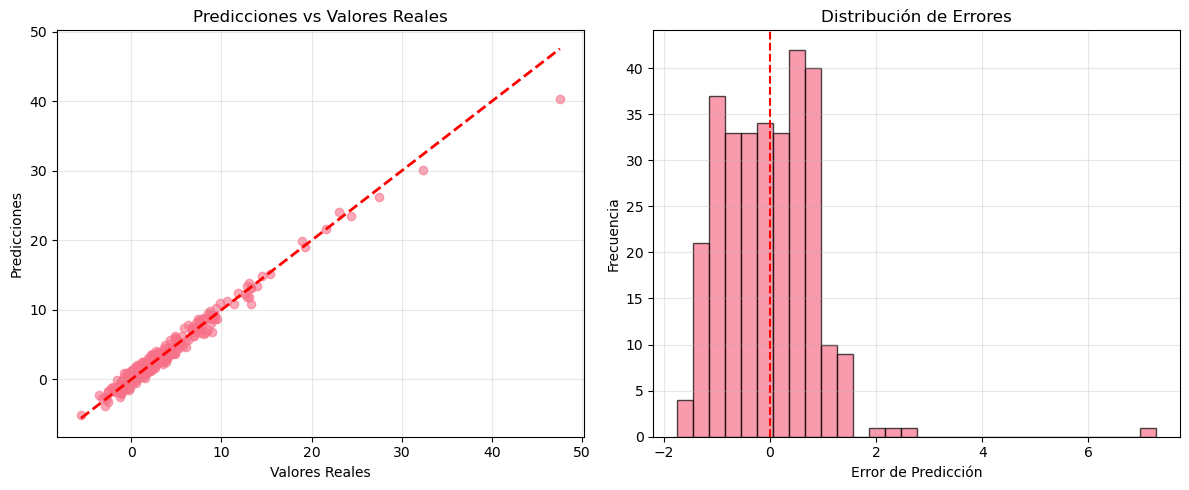

In [47]:
# Predicciones en el conjunto de prueba
y_pred = modelo.predict(X_test_scaled).flatten()

# Cálculo de métricas
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Métricas de evaluación en conjunto de prueba:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {np.sqrt(mse):.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")

# Visualización de predicciones vs valores reales
plt.figure(figsize=(12, 5))

# Scatter plot predicciones vs reales
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reales')
plt.ylabel('Predicciones')
plt.title('Predicciones vs Valores Reales')
plt.grid(True, alpha=0.3)

# Distribución de errores
plt.subplot(1, 2, 2)
errores = y_test - y_pred
plt.hist(errores, bins=30, alpha=0.7, edgecolor='black')
plt.axvline(x=0, color='r', linestyle='--')
plt.xlabel('Error de Predicción')
plt.ylabel('Frecuencia')
plt.title('Distribución de Errores')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Comparación contra un modelo de regresión

In [51]:
from sklearn.linear_model import LinearRegression

# Modelo lineal como baseline
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_scaled, y_train)

# Predicciones del modelo lineal
y_pred_lineal = modelo_lineal.predict(X_test_scaled)

# Métricas del modelo lineal
mse_lineal = mean_squared_error(y_test, y_pred_lineal)
mae_lineal = mean_absolute_error(y_test, y_pred_lineal)
r2_lineal = r2_score(y_test, y_pred_lineal)

print("Comparación con Modelo Lineal (Baseline):")
print("=" * 50)
print(f"{'Métrica':<10} {'Red Neuronal':<15} {'Lineal':<15} {'Mejora':<10}")
print(f"{'-' * 50}")
print(f"{'MSE':<10} {mse:.4f}{'':<5} {mse_lineal:.4f}{'':<5} {((mse_lineal-mse)/mse_lineal*100):.1f}%")
print(f"{'MAE':<10} {mae:.4f}{'':<5} {mae_lineal:.4f}{'':<5} {((mae_lineal-mae)/mae_lineal*100):.1f}%")
print(f"{'R²':<10} {r2:.4f}{'':<5} {r2_lineal:.4f}{'':<5} {((r2-r2_lineal)/r2_lineal*100):.1f}%")

Comparación con Modelo Lineal (Baseline):
Métrica    Red Neuronal    Lineal          Mejora    
--------------------------------------------------
MSE        0.8007      28.0580      97.1%
MAE        0.6911      3.0625      77.4%
R²         0.9739      0.0856      1037.9%
